In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torchvision
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor

# Train,Test ve Valid spliti

In [2]:
transform = transforms.Compose([
                                transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
                                transforms.ToTensor(),
                             transforms.Normalize(mean=(0.1307,), std=(0.3081,))
                             ] )
test_transform = transforms.Compose([
                                transforms.ToTensor(),
                             transforms.Normalize(mean=(0.1307,), std=(0.3081,))
                             ] )

In [3]:
# Tüm datasetleri en baştan ayrı ayrı indirip transformlarını atıyoruz
full_train_data = datasets.MNIST(root='datasets', train=True, download=True, transform=transform) 
valid_data = datasets.MNIST(root='datasets', train=True, download=True, transform=test_transform) 
test_data = datasets.MNIST(root='datasets', train=False, download=True, transform=test_transform) 

# Train ve Valid için 60.000'lik indeksi bölüyoruz (random_split'i sadece indeks almak için kullanıyoruz)
import torch
import numpy as np

# 42 seed'i ile 50.000'e 10.000 olacak şekilde rastgele indeks listesi oluşturuyoruz
indices = list(range(60000))
np.random.seed(42)
np.random.shuffle(indices)

train_idx, valid_idx = indices[:50000], indices[50000:]


train_data = torch.utils.data.Subset(full_train_data, train_idx)
valid_data = torch.utils.data.Subset(valid_data, valid_idx)

In [4]:
class_names = full_train_data.classes

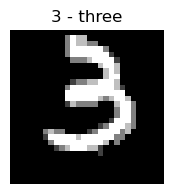

In [5]:
image, label = train_data[1]
image = image.permute(1, 2, 0)
plt.figure(figsize=(2, 2))
plt.gray()
plt.axis('off')
plt.imshow(image)
plt.title(class_names[label])
plt.show()

In [6]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32
train_dataloader = DataLoader(train_data,
                              batch_size=BATCH_SIZE,
                              shuffle=True)
test_dataloader = DataLoader(test_data,
                             batch_size=BATCH_SIZE,
                             shuffle=False)
valid_dataloader = DataLoader(valid_data,
                              batch_size=BATCH_SIZE,
                               shuffle=False)

32 lik batchler ile train, validation ve test datalarını yükledik. 
Train dataları shuffle edildi. Validation ve test dataları shuffle edilmedi.
Çünkü valid ve test datası ile eğitim yapılmayacak gereksiz işlem yükü olmaması için.

In [7]:
len(train_dataloader), len(valid_dataloader), len(test_dataloader)

(1563, 313, 313)

In [8]:
train_dataloader.dataset[0][0].shape

torch.Size([1, 28, 28])

Flaten ile derin ögrenmeye hazır hale getiriyoruz .Temsili kanıtı.

In [9]:
from torch import nn

flatten_model = nn.Flatten()
first_daata = train_dataloader.dataset[0][0]
flattened_data = flatten_model(first_daata)
print(first_daata.shape)
print(flattened_data.shape)

torch.Size([1, 28, 28])
torch.Size([1, 784])


# MLP mimari sınıfımız

In [10]:
class MNISTClassifier(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_shape)
        )
    def forward(self,x):
        return self.layer_stack(x)

In [11]:
HIDDEN_UNITS = 64
INPUT_SHAPE = 784
OUTPUT_SHAPE = len(class_names)

Model parametreleri tanımlanıyor.
İnput shape 28*28=784 vektörleştirdiğimiz için 784  feature sayımızdır .Hidden units katmanlardaki nöron sayısı ve outputshape olabilecek class sayımız .

In [12]:
torch.manual_seed(42)

model_0=MNISTClassifier(input_shape=INPUT_SHAPE,
                        hidden_units=HIDDEN_UNITS,
                        output_shape=OUTPUT_SHAPE)

Loss fonksiyonu ile Optimizer tanımlanıyor

In [13]:
loss_fn = nn.MultiMarginLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.001, weight_decay=0.0001)

# Sonlara dogru daha yavaş öğrenme için learning rate scheduler ekliyoruz
from torch.optim.lr_scheduler import StepLR
scheduler = StepLR(optimizer, step_size=10, gamma=0.3)

Accuracı hesaplarken direk fonksiyonu çagırarak kod daha temiz olsun diye tanımlandı

In [14]:
def calculate_accuracy(y_pred, y_true):
    correct = torch.eq(torch.argmax(y_pred, dim=1), y_true).sum().item()
    acc = (correct / len(y_pred)) * 100
    return acc

In [15]:
import torch

train_loss_history = []
train_acc_history = [] 
val_loss_history = []
val_acc_history = []

torch.manual_seed(42)
EPOCHS = 40

for epoch in range(EPOCHS):
    
    # --- EĞİTİM ---
    model_0.train() 
    train_loss, train_acc = 0, 0 
    
    
    for X, y_train in train_dataloader:
        y_pred = model_0(X)
        
        
        loss = loss_fn(y_pred, y_train)
        train_loss += loss.item() 
        train_acc += calculate_accuracy(y_pred, y_train) 
      
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
    # Epoch sonu ortalama alma
    train_loss /= len(train_dataloader)
    train_acc /= len(train_dataloader) 
    
    train_loss_history.append(train_loss) 
    train_acc_history.append(train_acc)

    # --- DOĞRULAMA ---
    model_0.eval() 
    val_loss, val_acc = 0, 0
    
    with torch.inference_mode(): 
        for X, y_val in valid_dataloader:
            val_pred = model_0(X)
            val_loss += loss_fn(val_pred, y_val).item()
            val_acc += calculate_accuracy(val_pred, y_val)
            
        val_loss /= len(valid_dataloader)
        val_acc /= len(valid_dataloader)
        
    val_loss_history.append(val_loss) 
    val_acc_history.append(val_acc)
    
    current_lr = scheduler.get_last_lr()[0]
    print(f"Epoch : {epoch} | Train Loss : {train_loss:.5f} | Val Loss : {val_loss:.5f} | Val Acc : {val_acc:.2f}% | LR: {current_lr}")
    
    scheduler.step()

print("\n--- Eğitim Tamamlandı.Test Başlıyor ---")

model_0.eval()
test_loss, test_acc = 0, 0

with torch.inference_mode():
    for X, y_test in test_dataloader:
        test_pred = model_0(X)
        test_loss += loss_fn(test_pred, y_test).item()
        test_acc += calculate_accuracy(test_pred, y_test)
        
    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)

print(f"Test Loss : {test_loss:.5f} | Test Accuracy : {test_acc:.2f}%")


Epoch : 0 | Train Loss : 0.11448 | Val Loss : 0.03512 | Val Acc : 91.49% | LR: 0.001
Epoch : 1 | Train Loss : 0.04724 | Val Loss : 0.02350 | Val Acc : 94.20% | LR: 0.001
Epoch : 2 | Train Loss : 0.03886 | Val Loss : 0.02288 | Val Acc : 94.30% | LR: 0.001
Epoch : 3 | Train Loss : 0.03493 | Val Loss : 0.01735 | Val Acc : 95.36% | LR: 0.001
Epoch : 4 | Train Loss : 0.03155 | Val Loss : 0.01849 | Val Acc : 95.50% | LR: 0.001
Epoch : 5 | Train Loss : 0.02930 | Val Loss : 0.01697 | Val Acc : 95.93% | LR: 0.001
Epoch : 6 | Train Loss : 0.02859 | Val Loss : 0.01333 | Val Acc : 96.28% | LR: 0.001
Epoch : 7 | Train Loss : 0.02776 | Val Loss : 0.01512 | Val Acc : 96.05% | LR: 0.001
Epoch : 8 | Train Loss : 0.02652 | Val Loss : 0.01442 | Val Acc : 96.31% | LR: 0.001
Epoch : 9 | Train Loss : 0.02544 | Val Loss : 0.01195 | Val Acc : 96.62% | LR: 0.001
Epoch : 10 | Train Loss : 0.01917 | Val Loss : 0.00890 | Val Acc : 97.27% | LR: 0.0003
Epoch : 11 | Train Loss : 0.01755 | Val Loss : 0.00963 | Val Ac

In [16]:
import matplotlib.pyplot as plt
import os
import json

def plot_all_results(train_loss, train_acc, val_loss, val_acc, test_loss=None, test_acc=None, save_path=None):
    """
    Metrikleri çizer ve eğer save_path verilmişse bilgisayara resim olarak kaydeder.
    """
    epochs = range(1, len(train_loss) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # 1. EĞİTİM (TRAIN)
    ax1 = axes[0]
    ax1.plot(epochs, train_loss, color='blue', marker='o', label='Train Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss Değeri', color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')
    ax1.grid(True, linestyle='--', alpha=0.5)
    ax1_acc = ax1.twinx() 
    ax1_acc.plot(epochs, train_acc, color='cyan', marker='s', label='Train Acc')
    ax1_acc.set_ylabel('Accuracy (%)', color='cyan')
    ax1_acc.tick_params(axis='y', labelcolor='cyan')
    axes[0].set_title('1. Eğitim (Train) Metrikleri')
    
    # 2. DOĞRULAMA (VALIDATION)
    ax2 = axes[1]
    ax2.plot(epochs, val_loss, color='red', marker='o', label='Val Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss Değeri', color='red')
    ax2.tick_params(axis='y', labelcolor='red')
    ax2.grid(True, linestyle='--', alpha=0.5)
    ax2_acc = ax2.twinx()
    ax2_acc.plot(epochs, val_acc, color='orange', marker='s', label='Val Acc')
    ax2_acc.set_ylabel('Accuracy (%)', color='orange')
    ax2_acc.tick_params(axis='y', labelcolor='orange')
    axes[1].set_title('2. Doğrulama (Validation) Metrikleri')
    
    # 3. TEST
    ax3 = axes[2]
    if test_loss is not None and test_acc is not None:
        ax3.bar(0, test_loss, color='purple', alpha=0.7, width=0.4)
        ax3.set_ylabel('Loss Değeri', color='purple')
        ax3.tick_params(axis='y', labelcolor='purple')
        ax3.text(0, test_loss + (test_loss * 0.02), f'{test_loss:.4f}', ha='center', va='bottom', fontweight='bold', color='purple')
        
        ax3_acc = ax3.twinx()
        ax3_acc.bar(1, test_acc, color='green', alpha=0.7, width=0.4)
        ax3_acc.set_ylabel('Accuracy (%)', color='green')
        ax3_acc.tick_params(axis='y', labelcolor='green')
        ax3_acc.text(1, test_acc + (test_acc * 0.02), f'{test_acc:.2f}%', ha='center', va='bottom', fontweight='bold', color='green')
        ax3.set_xticks([0, 1])
        ax3.set_xticklabels(['Test Loss', 'Test Accuracy'])
        ax3.set_xlim(-0.5, 1.5)
        axes[2].set_title('3. Nihai Test Sonuçları')
    else:
        ax3.text(0.5, 0.5, 'Test Verisi Belirtilmedi', ha='center', va='center', fontsize=12)
        axes[2].set_title('3. Nihai Test Sonuçları')
        ax3.axis('off')

    fig.tight_layout()
    
    # OTOMATİK KAYIT KISMI
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300) # dpi=300 yüksek kalite (4K) kayıt sağlar
        print(f"Grafik kaydedildi: {save_path}")
        
    plt.show()

In [17]:
import os
import json
import torch

def save_experiment_results(model, model_name, hyperparameters, train_loss, train_acc, val_loss, val_acc, test_loss, test_acc, base_dir="results"):
    # 1. Klasör yollarını oluştur
    os.makedirs(f"{base_dir}/models", exist_ok=True)
    os.makedirs(f"{base_dir}/metrics", exist_ok=True)
    os.makedirs(f"{base_dir}/plots", exist_ok=True)
    
    # 2. Modeli Kaydet
    model_save_path = f"{base_dir}/models/{model_name}.pth"
    torch.save(model.state_dict(), model_save_path)
    print(f"Model ağırlıkları kaydedildi: {model_save_path}")
    
    # 3. Hiperparametreleri ve Metrikleri BİRLEŞTİRİP JSON olarak kaydet
    experiment_data = {
        "Model_Name": model_name,
        "Hyperparameters": hyperparameters, # Sizin belirlediğiniz model ayarları buraya gelecek
        "Final_Results": {
            "test_loss": test_loss,
            "test_accuracy": test_acc
        },
        "Epoch_History": {
            "train_loss_history": train_loss,
            "train_acc_history": train_acc,
            "val_loss_history": val_loss,
            "val_acc_history": val_acc
        }
    }
    
    metrics_save_path = f"{base_dir}/metrics/{model_name}_info.json"
    with open(metrics_save_path, "w") as f:
        json.dump(experiment_data, f, indent=4)
    print(f"Tüm model ayarları ve sonuçları kaydedildi: {metrics_save_path}")
    
    # 4. Grafiği çiz ve kaydet
    plot_save_path = f"{base_dir}/plots/{model_name}_plot.png"
    plot_all_results(
        train_loss=train_loss, 
        train_acc=train_acc, 
        val_loss=val_loss, 
        val_acc=val_acc, 
        test_loss=test_loss, 
        test_acc=test_acc,
        save_path=plot_save_path
    )

Model ağırlıkları kaydedildi: results/models/mnist_Scheduler_Nöron_sayısı_artırıldı_v7.pth
Tüm model ayarları ve sonuçları kaydedildi: results/metrics/mnist_Scheduler_Nöron_sayısı_artırıldı_v7_info.json
Grafik kaydedildi: results/plots/mnist_Scheduler_Nöron_sayısı_artırıldı_v7_plot.png


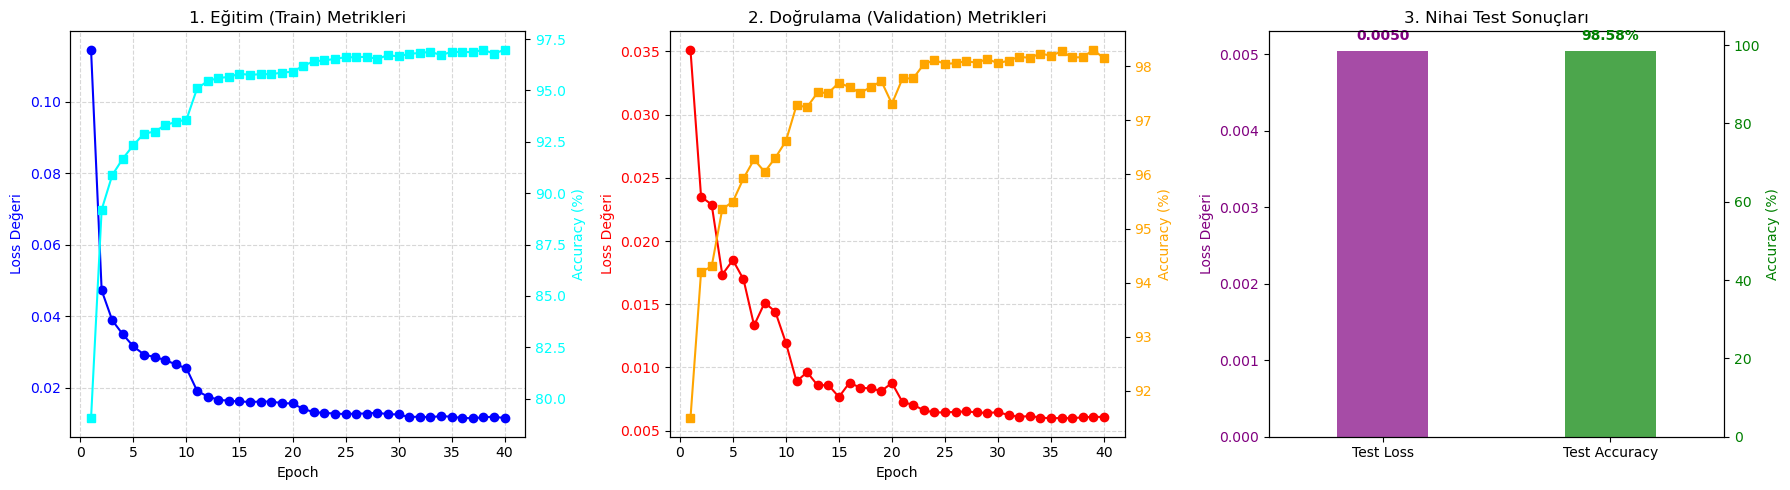

In [18]:
# Modelin mimarisinde ve eğitiminde kullandığınız tüm ayarlar:
current_hyperparameters = {
    "random_seed": 42,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "initial_learning_rate": 0.001,
    "scheduler": scheduler.state_dict() if 'scheduler' in locals() else "Yok",
    "optimizer": repr(optimizer),
    "loss_function": repr(loss_fn),
    "transform": repr(transform),
    "test_transform": repr(test_transform),
    "input_shape": INPUT_SHAPE,
    "hidden_units": HIDDEN_UNITS,
    "output_shape": OUTPUT_SHAPE
}

# Fonksiyonu çalıştırarak her şeyi otonom kaydediyoruz:
save_experiment_results(
    model=model_0,
    model_name="mnist_Scheduler_Nöron_sayısı_artırıldı_v7", 
    hyperparameters=current_hyperparameters, 
    train_loss=train_loss_history,
    train_acc=train_acc_history,
    val_loss=val_loss_history,
    val_acc=val_acc_history,
    test_loss=test_loss,
    test_acc=test_acc
)